# Gradient Boosting Regression — Step-by-Step Jupyter Notebook


---
Diabetes regression

The built-in `load_diabetes` dataset contains **442 observations and 10 numerical features**. The target is a quantitative measure of disease progression one year after baseline. The purpose here is demonstrating a **regression workflow**, not giving medical advice.

**Important:** We train on the training set and evaluate on the test set. We do not use the test set for hyperparameter tuning.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV

# Load a built-in regression dataset
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target

print("Features:", X.shape)
print("Target:", y.shape)
print(X.head())

Features: (442, 10)
Target: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


### Step 8 — Train/test split and baseline model

In [18]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

baseline_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Test MSE:  {mse:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²:   {r2:.3f}")

Test MSE:  2900.98
Test RMSE: 53.86
Test R²:   0.452


### Step 9 — Plot actual vs predicted values

Points nearer the diagonal have predictions closer to actual target values.

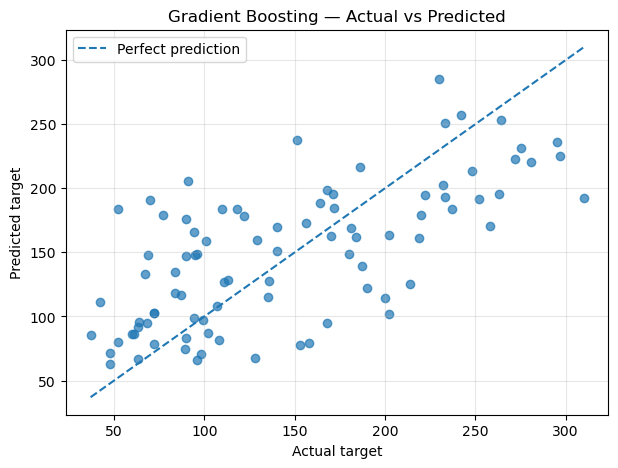

In [19]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], linestyle="--", label="Perfect prediction")

plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Gradient Boosting — Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Step 10 — Tune the hyperparameters using GridSearchCV

This small search is intentionally limited so it runs comfortably during class. `neg_root_mean_squared_error` is negative because scikit-learn treats **higher scores as better**. To report RMSE, change the sign back to positive.

In [20]:
param_grid = {
    "n_estimators": [50, 100],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
    "subsample": [0.8, 1.0]
}

grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=3,
    n_jobs=1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation RMSE:", round(-grid.best_score_, 2))

Best parameters: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 50, 'subsample': 0.8}
Best cross-validation RMSE: 57.48


### Step 11 — Evaluate the best tuned model on the test set

In [21]:
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

print("Baseline test RMSE:", round(rmse, 2))
print("Tuned test RMSE:   ", round(np.sqrt(mean_squared_error(y_test, best_pred)), 2))
print("Tuned test R²:     ", round(r2_score(y_test, best_pred), 3))

Baseline test RMSE: 53.86
Tuned test RMSE:    52.38
Tuned test R²:      0.482


### Step 12 — Inspect feature importance

Tree feature importance reports how much the model relied on features for reducing split impurity. It does **not** prove causation.

bmi    0.413
s5     0.274
bp     0.104
s2     0.046
s3     0.043
age    0.040
s6     0.026
s4     0.025
s1     0.018
sex    0.011
dtype: float64


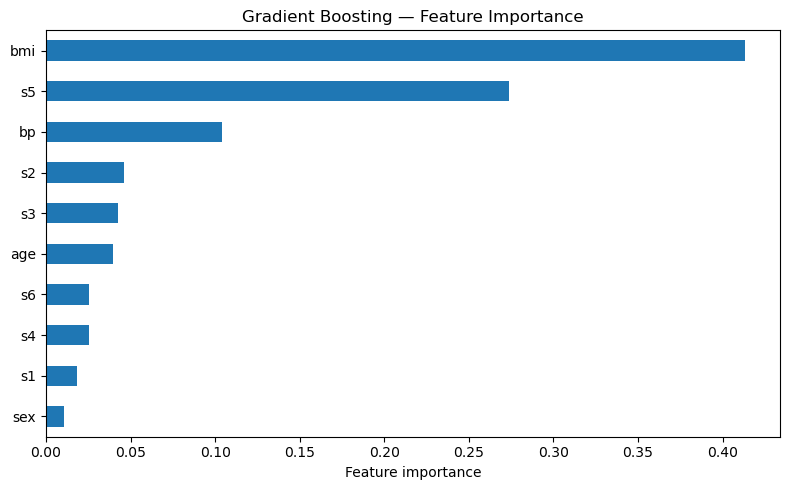

In [22]:
importance = pd.Series(
    best_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.round(3))

plt.figure(figsize=(8, 5))
importance.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Gradient Boosting — Feature Importance")
plt.tight_layout()
plt.show()

### Student practice

1. In **Part A**, change `learning_rate` to `1.0`. How do the stage-wise predictions change?
2. In **Part A**, change `max_depth` to `2`. Do all tree splits remain the same? Why might not?
3. In **Part B**, compare `n_estimators=50` and `n_estimators=200` on the same train/test split.
4. In **Part B**, explain in one sentence what `subsample=0.8` means.
5. In **Part B**, why should we select hyperparameters using cross-validation on **training data**, rather than the test set?

**Key takeaway:** Gradient Boosting starts with a simple prediction and learns a sequence of regression trees to correct prediction errors. For squared-error loss, these corrections are based on residuals.